# LSTM. Трансформер. Механизм внимания (ноутбук)

> Этот ноутбук является практическим дополнением к лекции №9 по глубокому обучению. Мы углубим наше понимание рекуррентных нейронных сетей (RNN), рассмотрим их модификации Long Short-Term Memory (LSTM) и Gated Recurrent Unit (GRU), а также познакомимся с механизмом внимания и архитектурой Трансформера. Основная задача семинара — реализовать посимвольную генерацию текста (на примере анекдотов) с помощью LSTM-сети.

---

## Цели улучшения:

1.  **Детальные объяснения:** Каждый блок кода будет сопровождаться подробным описанием того, что он делает, зачем и как он соотносится с теоретическим материалом лекции.
2.  **Разбор PyTorch модулей:** Подробно объясним параметры `nn.RNN`, `nn.GRU`, `nn.LSTM`, `nn.Embedding`, `nn.Linear` и их влияние.
3.  **Понимание форм тензоров:** Разберем, как изменяются формы данных при прохождении через слои, особенно акцентируя внимание на `batch_first=True/False`.
4.  **Логика обучения и генерации:** Пошагово объясним, как формируются входные и целевые данные для обучения, а также механизм генерации текста.
5.  **Гиперпараметры:** Обоснуем выбор гиперпараметров и предложим идеи для дальнейшего тюнинга.
6.  **Устранение "поверхностности":** Разъясним все моменты, которые могут быть непонятны без дополнительных материалов, основываясь на задачах, поставленных студентами.


In [1]:
import torch
import torch.nn as nn # Модуль для создания нейронных сетей
import torch.optim as optim # Модуль для оптимизаторов (Adam, SGD и т.д.)

import matplotlib.pyplot as plt # Для построения графиков
from IPython.display import clear_output # Для очистки вывода в Jupyter/Colab
from tqdm.auto import tqdm # Для красивых прогресс-баров

# Добавим импорты для работы с данными
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn.utils.rnn import pad_sequence # Специальная функция для паддинга последовательностей

## 📚 Данные: Анекдоты для посимвольной генерации

Мы будем использовать набор данных из 125 тысяч анекдотов. Задача — обучить рекуррентную нейронную сеть генерировать новые анекдоты, символ за символом. Такой подход (посимвольная генерация) проще реализовать и обучить для коротких текстов, чем пословную генерацию, поскольку размер словаря символов гораздо меньше, чем слов.


In [2]:
aneks = []

# Открываем файл с анекдотами и читаем их
# Предполагается, что файл anek.txt находится в той же директории, что и ноутбук
with open('anek.txt', 'r', encoding='utf-8') as f: # Указываем кодировку UTF-8 для корректной работы с русским текстом
    aneks.extend(f.read().split('\n')) # Разделяем текст на отдельные анекдоты по символу новой строки

In [3]:
len(aneks) # Выводим количество загруженных анекдотов

125103

### `Vocabulary` класс: Создание словаря символов

Этот класс отвечает за создание и управление словарем всех символов, которые могут встретиться в наших анекдотах. Он также предоставляет методы для кодирования текста в последовательность числовых индексов и обратно.


In [4]:
class Vocabulary:
    def __init__(self):
        # 1. Специальные символы
        # '_' (underscore) - Start Of Sequence (SOS) - начало последовательности
        # '#' (hash) - End Of Sequence (EOS) - конец последовательности
        # '<' (less than) - Padding (PAD) - символ для дополнения коротких последовательностей до максимальной длины
        self.vocabulary = ['_', '#', '<'] 
        
        # 2. Русский алфавит (строчные буквы)
        self.vocabulary.extend('абвгдеёжзийклмнопрстуфхцчшщъыьэюя')
        
        # 3. Русский алфавит (заглавные буквы)
        self.vocabulary.extend('абвгдеёжзийклмнопрстуфхцчшщъыьэюя'.upper())
        
        # 4. Цифры, пробел и некоторые знаки препинания
        self.vocabulary.extend('0123456789 ,.!?-')

        # Создаем два словаря для быстрого преобразования:
        # _idx2char: числовой индекс -> символ
        # _char2idx: символ -> числовой индекс
        self._idx2char = {i: char for i, char in enumerate(self.vocabulary)}
        self._char2idx = {char: i for i, char in enumerate(self.vocabulary)}

    def get_vocabulary(self):
        """Возвращает список всех символов в словаре."""
        return self.vocabulary

    def idx2char(self, idx: int):
        """Преобразует числовой индекс в символ. Если индекс неизвестен, возвращает PAD."""
        if idx not in self._idx2char:
            return '<' # Возвращаем символ паддинга для неизвестных индексов

        return self._idx2char[idx]

    def char2idx(self, char: str):
        """Преобразует символ в числовой индекс. Если символ неизвестен, возвращает индекс PAD."""
        if char not in self._char2idx:
            return self.get_pad() # Возвращаем индекс паддинга для неизвестных символов

        return self._char2idx[char]

    def encode(self, text):
        """
        Кодирует входной текст в последовательность числовых индексов.
        Добавляет специальные символы SOS в начало и EOS в конец.
        Пример: "Привет" -> [SOS_idx, П_idx, р_idx, и_idx, в_idx, е_idx, т_idx, EOS_idx]
        """
        result = [self.char2idx(char) for char in text]

        # Добавляем SOS и EOS токены, что сигнализирует модели о начале и конце последовательности
        result = [self.get_sos()] + result + [self.get_eos()]

        return result

    # Вспомогательные функции для получения индексов специальных символов
    def get_sos(self):
        return self.char2idx('_')

    def get_eos(self):
        return self.char2idx('#')

    def get_pad(self):
        return self.char2idx('<')

### `Anekdotes` класс: PyTorch Dataset

Класс `Anekdotes` наследуется от `torch.utils.data.Dataset` и предназначен для удобного доступа к данным. Он позволяет PyTorch `DataLoader` загружать анекдоты по одному или батчами.

In [5]:
from torch.utils.data import Dataset # Базовый класс для датасетов в PyTorch


class Anekdotes(Dataset):
    def __init__(self, aneks):
        self.aneks = aneks # Список анекдотов
        self.vocab = Vocabulary() # Создаем экземпляр нашего словаря

    def __getitem__(self, idx):
        """
        Возвращает один элемент датасета по его индексу.
        В нашем случае - это один анекдот, закодированный в LongTensor.
        """
        # Кодируем анекдот с помощью словаря и преобразуем в LongTensor
        # LongTensor необходим, так как PyTorch ожидает целочисленные индексы для Embedding слоев
        return torch.LongTensor(self.vocab.encode(self.aneks[idx]))

    def __len__(self):
        """
        Возвращает общее количество элементов в датасете (количество анекдотов).
        """
        return len(self.aneks)

In [6]:
dataset = Anekdotes(aneks) # Создаем экземпляр датасета

In [7]:
# Посмотрим на 10-й анекдот в виде индексов
print(dataset[10])

tensor([ 0, 61, 22, 12, 20, 15, 12, 26, 79, 22, 18, 19, 12, 15, 79,  4, 23, 20,
        10, 23, 13, 14, 23, 81, 79, 55, 18, 15, 32, 14, 18, 79, 27,  8, 20,  8,
        11, 79,  7,  5,  3, 79, 27,  3, 21,  3, 79,  8, 16, 23, 79, 23,  7,  3,
        15, 18, 21, 32, 79,  8,  8, 79, 23, 22, 18, 19, 12, 22, 32, 81,  1])


In [8]:
# Чтобы понять, что это за символы, посмотрим на сам анекдот:
print(aneks[10])

Штирлиц топил буржуйку. Только через два часа ему удалось ее утопить.


*   `0` - это индекс для символа `_` (SOS - начало последовательности).
*   `61` - это индекс для символа `Ш`.
*   `1` - это индекс для символа `#` (EOS - конец последовательности).

### Разделение данных и `collate_fn` для `DataLoader`

Для обучения нейронной сети мы разделим наш датасет на обучающую и валидационную выборки. `DataLoader` будет загружать данные батчами, но поскольку анекдоты имеют разную длину, нам потребуется специальная функция `collate_fn` для их выравнивания (padding).

In [9]:
from torch.utils.data import random_split # Функция для случайного разделения датасета


# Разделяем датасет на обучающую (90%) и валидационную (10%) части
train_dataset, valid_dataset = random_split(
    dataset,
    (int(len(dataset) * 0.9), len(dataset) - int(len(dataset) * 0.9))
)

# Получаем индекс символа паддинга из нашего словаря.
# Он будет использоваться для заполнения коротких последовательностей.
pad_idx = dataset.vocab.get_pad()


def collate_fn(batch):
    """
    Функция для "склеивания" элементов батча в один тензор.
    Необходима, потому что последовательности в батче имеют разную длину.
    """
    # 1. Обрезаем каждую последовательность до максимальной длины 256 символов.
    # Это делается для экономии памяти и вычислительных ресурсов, так как слишком длинные
    # последовательности могут сильно замедлить обучение и нести много "шума".
    # [b[:256] for b in batch] создает список укороченных тензоров.

    # 2. pad_sequence: выравнивает все последовательности в батче до одной длины.
    #    - padding_value=pad_idx: короткие последовательности дополняются символом PAD.
    #    - batch_first=True: указывает, что размерность батча должна быть первой.
    #      Тензор будет иметь форму (batch_size, sequence_length).
    return pad_sequence([b[:256] for b in batch], padding_value=pad_idx, batch_first=True)

In [10]:
from torch.utils.data import DataLoader # Для загрузки данных батчами


# Создаем DataLoader для обучающей выборки
train_loader = DataLoader(
    train_dataset,
    batch_size=256, # Размер батча - количество анекдотов, обрабатываемых за один раз
    collate_fn=collate_fn, # Наша функция для выравнивания последовательностей
    pin_memory=True, # Ускоряет передачу данных на GPU, если доступно
    shuffle=True # Перемешиваем данные в обучающей выборке на каждой эпохе
)

# Создаем DataLoader для валидационной выборки
valid_loader = DataLoader(
    valid_dataset,
    batch_size=256,
    collate_fn=collate_fn,
    pin_memory=True,
    shuffle=False # Не перемешиваем валидационные данные, чтобы результаты были воспроизводимы
)


## 🧠 Модель: Рекуррентные слои PyTorch

В PyTorch реализованы основные типы рекуррентных слоев. Рассмотрим их особенности и параметры.

### `nn.RNN`: Базовый рекуррентный слой

Базовый `nn.RNN` реализует простую рекуррентную ячейку, где скрытое состояние обновляется с помощью гиперболического тангенса ($\tanh$) или ReLU.

$$h_t = \tanh\left( x_tW_{xh}^T + b_{xh} + h_{t-1}W_{hh}^T + b_{hh} \right)$$

Либо, если `bias=False` (сдвиги отсутствуют):

$$h_t = \tanh\left( x_tW_{xh}^T + h_{t-1}W_{hh}^T \right)$$

**Основные параметры `nn.RNN`:**

*   `input_size` (int): Размерность входных векторов `x_t`. Если вы используете `nn.Embedding`, то это будет `emb_size`.
*   `hidden_size` (int): Размерность скрытого состояния `h_t`. Это ключевой гиперпараметр, определяющий "ёмкость памяти" RNN.
*   `num_layers` (int, по умолчанию 1): Количество рекуррентных слоев, сложенных друг на друга (stacked RNNs). Каждый следующий слой принимает скрытые состояния предыдущего слоя в качестве своих входов.
*   `dropout` (float, по умолчанию 0): Если `num_layers > 1`, применяется дропаут (регуляризация) к выходам каждого слоя, кроме последнего. Помогает предотвратить переобучение.
*   `bidirectional` (bool, по умолчанию `False`): Если `True`, RNN становится двунаправленной (Bidirectional RNN), обрабатывая последовательность в двух направлениях.


In [11]:
# Создаем простой RNN слой
# input_size=3: каждый входной элемент (например, эмбеддинг символа) имеет размерность 3.
# hidden_size=6: скрытое состояние h_t будет вектором из 6 чисел.
layer_rnn = nn.RNN(input_size=3, hidden_size=6)
print(layer_rnn)

RNN(3, 6)


**Параметры, которые обучаются в `nn.RNN`:**

RNN-слой содержит матрицы весов и векторы сдвигов (bias) для каждого слоя.
*   `weight_ih_l0`: $W_{xh}$ (Input-to-Hidden) - матрица весов, применяемая к **входному вектору `x_t`** для 0-го слоя.
    *   Размер: `(hidden_size, input_size)`. Она преобразует `input_size` в `hidden_size`.
*   `weight_hh_l0`: $W_{hh}$ (Hidden-to-Hidden) - матрица весов, применяемая к **предыдущему скрытому состоянию `h_t-1`** для 0-го слоя.
    *   Размер: `(hidden_size, hidden_size)`. Она преобразует `hidden_size` в `hidden_size`.
*   `bias_ih_l0`: $b_{xh}$ - вектор сдвига для `x_t`.
    *   Размер: `(hidden_size)`.
*   `bias_hh_l0`: $b_{hh}$ - вектор сдвига для `h_t-1`.
    *   Размер: `(hidden_size)`.

Если `num_layers > 1`, будут также `weight_ih_l1`, `weight_hh_l1` и т.д.

In [12]:
print("Weight matrix for previous hidden state (W_hh):")
print(layer_rnn.weight_hh_l0)
print("Shape:", layer_rnn.weight_hh_l0.shape) # (hidden_size, hidden_size)

print("\nWeight matrix for current input (W_xh):")
print(layer_rnn.weight_ih_l0)
print("Shape:", layer_rnn.weight_ih_l0.shape) # (hidden_size, input_size)

print("\nBias vector for previous hidden state (b_hh):")
print(layer_rnn.bias_hh_l0)
print("Shape:", layer_rnn.bias_hh_l0.shape) # (hidden_size)

print("\nBias vector for current input (b_xh):")
print(layer_rnn.bias_ih_l0)
print("Shape:", layer_rnn.bias_ih_l0.shape) # (hidden_size)

Weight matrix for previous hidden state (W_hh):
Parameter containing:
tensor([[-0.3836, -0.1778, -0.0592, -0.1214,  0.0005, -0.0690],
        [ 0.3402,  0.1883, -0.1133, -0.1762, -0.0464,  0.2678],
        [ 0.1680,  0.1262, -0.0392,  0.1321, -0.0841,  0.3553],
        [-0.1168,  0.2998,  0.2400, -0.3268,  0.2895, -0.1326],
        [-0.1435,  0.0555,  0.2833, -0.2861, -0.3322, -0.0026],
        [ 0.3980, -0.2580,  0.1972,  0.4016,  0.4059, -0.0139]],
       requires_grad=True)
Shape: torch.Size([6, 6])

Weight matrix for current input (W_xh):
Parameter containing:
tensor([[ 0.1858, -0.1107,  0.3990],
        [ 0.0804,  0.1935, -0.3299],
        [ 0.0699,  0.1022, -0.1115],
        [ 0.0856, -0.4044, -0.3630],
        [ 0.3144,  0.0563, -0.4064],
        [-0.0720,  0.3151,  0.3195]], requires_grad=True)
Shape: torch.Size([6, 3])

Bias vector for previous hidden state (b_hh):
Parameter containing:
tensor([ 0.3740, -0.2925,  0.1338,  0.4047, -0.3556,  0.0716],
       requires_grad=True)
S

#### Параметр `batch_first` (`nn.RNN`, `nn.GRU`, `nn.LSTM`)

Этот параметр очень важен для корректной работы с данными. Он определяет, какая размерность тензора будет соответствовать размеру батча.

*   `batch_first=True` (по умолчанию для многих высокоуровневых фреймворков и рекомендуется):
    *   Вход: `(batch_size, sequence_length, input_size)`
    *   Выход: `(batch_size, sequence_length, hidden_size)` для всех скрытых состояний (`hs`)
    *   Выход: `(num_layers * num_directions, batch_size, hidden_size)` для последнего скрытого состояния (`h_last`)
*   `batch_first=False` (по умолчанию в PyTorch `nn.RNN`):
    *   Вход: `(sequence_length, batch_size, input_size)`
    *   Выход: `(sequence_length, batch_size, hidden_size)` для всех скрытых состояний (`hs`)
    *   Выход: `(num_layers * num_directions, batch_size, hidden_size)` для последнего скрытого состояния (`h_last`)


In [13]:
batch_size = 5
seq_len = 7
input_dim = 3

# Пример с batch_first=True
print("--- batch_first=True ---")
layer_rnn_bf_true = nn.RNN(input_size=input_dim, hidden_size=6, batch_first=True)
# Создаем случайный входной тензор: (количество объектов в батче, длина последовательности, размерность элемента)
x_bf_true = torch.randn(batch_size, seq_len, input_dim)

# Пропускаем через RNN. Возвращает два тензора:
# hs (hidden states): все скрытые состояния для каждого шага последовательности.
# h_last (last hidden state): последнее скрытое состояние.
hs_bf_true, h_last_bf_true = layer_rnn_bf_true(x_bf_true)

print("Input shape (batch_first=True):", x_bf_true.shape)
print("Output (hs) shape (batch_first=True):", hs_bf_true.shape) # (batch_size, seq_len, hidden_size)
print("Last hidden state (h_last) shape (batch_first=True):", h_last_bf_true.shape) # (num_layers*num_directions, batch_size, hidden_size)
# В нашем случае num_layers=1, num_directions=1, поэтому (1, 5, 6)

print("\n--- batch_first=False (PyTorch default) ---")
layer_rnn_bf_false = nn.RNN(input_size=input_dim, hidden_size=6, batch_first=False)
# Создаем случайный входной тензор: (длина последовательности, количество объектов в батче, размерность элемента)
x_bf_false = torch.randn(seq_len, batch_size, input_dim)

hs_bf_false, h_last_bf_false = layer_rnn_bf_false(x_bf_false)

print("Input shape (batch_first=False):", x_bf_false.shape)
print("Output (hs) shape (batch_first=False):", hs_bf_false.shape) # (seq_len, batch_size, hidden_size)
print("Last hidden state (h_last) shape (batch_first=False):", h_last_bf_false.shape) # (num_layers*num_directions, batch_size, hidden_size)
# Заметим, что h_last имеет одинаковую структуру независимо от batch_first

--- batch_first=True ---
Input shape (batch_first=True): torch.Size([5, 7, 3])
Output (hs) shape (batch_first=True): torch.Size([5, 7, 6])
Last hidden state (h_last) shape (batch_first=True): torch.Size([1, 5, 6])

--- batch_first=False (PyTorch default) ---
Input shape (batch_first=False): torch.Size([7, 5, 3])
Output (hs) shape (batch_first=False): torch.Size([7, 5, 6])
Last hidden state (h_last) shape (batch_first=False): torch.Size([1, 5, 6])


**Важно:** Для нашего `DataLoader` и `collate_fn` мы используем `batch_first=True`, поэтому и в модели будем использовать `batch_first=True` для согласованности.

### `nn.GRU`: Gated Recurrent Unit

`nn.GRU` реализует архитектуру Gated Recurrent Unit, которая решает проблемы затухающих градиентов и долгосрочных зависимостей. GRU имеет вентили сброса (`r_t`) и обновления (`z_t`).

$$r_t = \sigma\left( x_t W_{xr}^T + b_{xr} + h_{t-1}W_{hr}^T + b_{hr} \right)$$
$$z_t = \sigma\left( x_t W_{xz}^T + b_{xz} + h_{t-1}W_{hz}^T + b_{hz} \right)$$
$$\hat{h_t} = \tanh\left( x_tW_{xh}^T + b_{xh} + r_t \odot (h_{t-1}W_{hh}^T + b_{hh}) \right)$$
$$h_t = (1 - z_t) \odot \hat{h_t} + z_t \odot h_{t-1}$$
где $\odot$ - поэлементное умножение, $\sigma$ - функция сигмоиды.

Параметры `nn.GRU` аналогичны `nn.RNN`. Однако, за счет наличия нескольких вентилей (reset, update) и кандидата на скрытое состояние, количество матриц весов и bias-векторов увеличивается (умножается на 3 по сравнению с `nn.RNN`).


In [14]:
layer_gru = nn.GRU(input_size=3, hidden_size=6)
print(layer_gru)

GRU(3, 6)


In [15]:
# Посмотрим на параметры GRU. Заметим, что их размерности больше.
# Например, для Weight_hh_l0: 3 * hidden_size на hidden_size
# Это связано с тем, что внутри GRU есть 3 логических матрицы весов (для z_t, r_t, h_tilde_t)
print("Weight matrix for previous hidden state (W_hr, W_hz, W_hh):")
print(layer_gru.weight_hh_l0.shape) # (3 * hidden_size, hidden_size)

print("\nWeight matrix for current input (W_xr, W_xz, W_xh):")
print(layer_gru.weight_ih_l0.shape) # (3 * hidden_size, input_size)

print("\nBias vector for previous hidden state (b_hr, b_hz, b_hh):")
print(layer_gru.bias_hh_l0.shape) # (3 * hidden_size)

print("\nBias vector for current input (b_xr, b_xz, b_xh):")
print(layer_gru.bias_ih_l0.shape) # (3 * hidden_size)

Weight matrix for previous hidden state (W_hr, W_hz, W_hh):
torch.Size([18, 6])

Weight matrix for current input (W_xr, W_xz, W_xh):
torch.Size([18, 3])

Bias vector for previous hidden state (b_hr, b_hz, b_hh):
torch.Size([18])

Bias vector for current input (b_xr, b_xz, b_xh):
torch.Size([18])


### `nn.LSTM`: Long Short-Term Memory

`nn.LSTM` реализует архитектуру Long Short-Term Memory, которая также решает проблемы затухающих градиентов и долгосрочных зависимостей, используя три вентиля: входной (input), забывающий (forget) и выходной (output), а также отдельное состояние ячейки `c_t` (cell state) в дополнение к скрытому состоянию `h_t`.
Формулы LSTM более сложны, чем у GRU, но концептуально преследуют ту же цель - управление потоком информации для долгосрочной памяти.

Параметры `nn.LSTM` аналогичны `nn.RNN` и `nn.GRU`. У LSTM количество матриц весов и bias-векторов умножается на 4 (для каждого из 4 вентилей/компонентов ячейки).

*   **Ссылки на документацию PyTorch для подробностей:**
    *   [nn.RNN](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html)
    *   [nn.GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html)
    *   [nn.LSTM](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)


In [16]:
layer_lstm = nn.LSTM(input_size=3, hidden_size=6)
print(layer_lstm)

LSTM(3, 6)


### `AnekdoteRNN` Модель: Наша генеративная сеть

Мы построим модель для генерации анекдотов, используя `nn.LSTM` в качестве основного рекуррентного слоя.


In [17]:
class AnekdoteRNN(nn.Module):
    def __init__(self, num_tokens: int, emb_size: int=32, hidden_size: int=256):
        """
        Инициализация модели AnekdoteRNN.
        
        Args:
            num_tokens (int): Размер словаря (количество уникальных символов).
            emb_size (int): Размерность векторов-эмбеддингов для каждого символа. Гиперпараметр.
            hidden_size (int): Размерность скрытого состояния LSTM. Гиперпараметр.
        """
        super().__init__()

        # 1. Слой эмбеддингов (nn.Embedding)
        # Преобразует дискретные числовые индексы символов в плотные векторные представления.
        # - num_tokens: Количество возможных индексов (размер словаря).
        # - emb_size: Размерность вектора, в который будет преобразован каждый индекс.
        # - padding_idx: Указываем индекс символа паддинга. Эмбеддинг для этого индекса будет
        #   всегда нулевым вектором и не будет участвовать в обучении, что экономит ресурсы.
        self.embedding = nn.Embedding(num_tokens, emb_size, padding_idx=pad_idx)

        # 2. Основной рекуррентный слой (nn.LSTM)
        # LSTM выбрана из-за ее способности работать с долгосрочными зависимостями,
        # что важно для связной генерации текста.
        # - input_size: Размерность входных векторов для LSTM. Здесь это emb_size,
        #   так как на вход LSTM приходят эмбеддинги символов.
        # - hidden_size: Размерность скрытого состояния LSTM (h_t и c_t).
        # - num_layers: Количество слоев LSTM, сложенных друг на друга. num_layers=4
        #   делает модель глубокой, позволяя ей улавливать более сложные зависимости.
        # - dropout: Вероятность дропаута между слоями LSTM. dropout=0.3
        #   помогает предотвратить переобучение. При num_layers=1 дропаут не применяется.
        # - batch_first: True указывает, что входные и выходные тензоры будут иметь
        #   размерность (batch_size, sequence_length, features). Это соответствует
        #   формату данных из нашего DataLoader.
        self.rnn = nn.LSTM(
            input_size=emb_size,
            hidden_size=hidden_size,
            num_layers=4,
            dropout=0.3,
            batch_first=True
        )

        # 3. Выходной слой (output classifier)
        # Преобразует скрытое состояние LSTM в логиты для каждого символа в словаре.
        # - nn.Sequential: Последовательность слоев.
        # - nn.Linear(hidden_size, hidden_size): Первый полносвязный слой.
        #   Принимает скрытое состояние h_t (размер hidden_size) и преобразует его.
        # - nn.LeakyReLU(): Функция активации LeakyReLU.
        #   Важное замечание: Хотя ReLU и LeakyReLU не рекомендуются для *внутренних*
        #   активаций RNN/LSTM/GRU из-за проблем со взрывом значений (как обсуждалось в лекции),
        #   их использование *после* рекуррентного слоя, в выходном классификаторе,
        #   является абсолютно нормальным и даже желательным. Здесь LeakyReLU добавляет
        #   нелинейности между двумя линейными слоями, помогая модели выучить более
        #   сложные зависимости для предсказания следующего символа.
        # - nn.Linear(hidden_size, num_tokens): Второй полносвязный слой.
        #   Преобразует промежуточное представление в логиты для каждого из num_tokens
        #   возможных символов в словаре.
        self.output = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.LeakyReLU(),
            nn.Linear(hidden_size, num_tokens)
        )

    def forward(self, x):
        """
        Прямой проход данных через модель.
        
        Args:
            x (torch.LongTensor): Входной тензор с числовыми индексами символов.
                                  Форма: (batch_size, sequence_length).
        
        Returns:
            torch.Tensor: Логиты для каждого символа на каждом шаге последовательности.
                          Форма: (batch_size, sequence_length, num_tokens).
        """
        # 1. Пропускаем входные индексы через слой эмбеддингов
        # Форма после embedding: (batch_size, sequence_length, emb_size)
        x = self.embedding(x)
        
        # 2. Пропускаем эмбеддинги через LSTM слой
        # self.rnn(x) возвращает кортеж (output, (h_n, c_n)):
        # - output: Все скрытые состояния (h_t) для каждого шага последовательности.
        #   Форма: (batch_size, sequence_length, hidden_size)
        # - (h_n, c_n): Последние скрытое состояние и состояние ячейки.
        #   В нашей задаче посимвольной генерации нам нужны скрытые состояния со всех шагов,
        #   чтобы предсказывать следующий символ после каждого входного символа,
        #   поэтому мы берем только 'output' и игнорируем '(h_n, c_n)' с помощью '_'.
        x, _ = self.rnn(x)
        
        # 3. Пропускаем выходные скрытые состояния LSTM через выходной классификатор
        # Форма после output: (batch_size, sequence_length, num_tokens)
        # Каждое hidden_state (h_t) преобразуется в вектор логитов размером num_tokens,
        # представляющий предсказание следующего символа.
        x  = self.output(x)

        return x

### Создаем экземпляр нашей модели

In [18]:
# num_tokens - это размер нашего словаря, который мы получаем из dataset.vocab
model = AnekdoteRNN(num_tokens=len(dataset.vocab.get_vocabulary()))
print(model)

AnekdoteRNN(
  (embedding): Embedding(85, 32, padding_idx=2)
  (rnn): LSTM(32, 256, num_layers=4, batch_first=True, dropout=0.3)
  (output): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=256, out_features=85, bias=True)
  )
)


## ⚙️ Функции для обучения и оценки

Для обучения модели нам потребуются функции `train` (для одного этапа обучения), `evaluate` (для оценки на валидационной выборке), а также вспомогательные функции для визуализации и полного цикла обучения.

### `train` функция: Обучение модели на одном батче


In [19]:
from tqdm.auto import tqdm

def train(model, device, train_loader, optimizer, loss_fn): # Добавили параметры для большей гибкости
    """
    Выполняет один этап обучения модели на всех батчах обучающей выборки.

    Args:
        model (nn.Module): Обучаемая модель.
        device (torch.device): Устройство (CPU/GPU), на котором производится обучение.
        train_loader (DataLoader): Загрузчик данных для обучающей выборки.
        optimizer (torch.optim.Optimizer): Оптимизатор (например, Adam).
        loss_fn (nn.Module): Функция потерь (например, CrossEntropyLoss).

    Returns:
        float: Среднее значение функции потерь на обучающей выборке за эпоху.
    """
    model.train() # Переводим модель в режим обучения (активирует dropout, batchnorm и т.д.)
    train_loss = 0

    # Проходим по всем батчам в train_loader
    for x in tqdm(train_loader, desc='Train'):
        x = x.to(device) # Перемещаем батч данных на указанное устройство (GPU/CPU)

        optimizer.zero_grad() # Обнуляем градиенты перед началом нового шага обратного распространения

        # --- Подготовка входных и целевых данных для обучения ---
        # Мы решаем задачу предсказания следующего символа.
        # x_input: Все символы, кроме последнего. Они подаются в модель для предсказания.
        # x_target: Все символы, кроме первого. Это правильные ответы, которые модель должна предсказать.
        # Пример: если x = [SOS, C1, C2, C3, EOS]
        # x_input  = [SOS, C1, C2, C3]
        # x_target = [C1,  C2, C3, EOS]
        # Таким образом, модель учится предсказывать C1 после SOS, C2 после C1 и т.д.

        # model(x[:, :-1]) -> выход модели для x_input.
        # output.transpose(1, 2) -> меняем размерности для CrossEntropyLoss.
        # Подробнее об этом ниже.
        output = model(x[:, :-1]).transpose(1, 2)
        
        # Вычисляем функцию потерь.
        # output - это логиты модели, x[:, 1:] - это целевые индексы символов.
        loss = loss_fn(output, x[:, 1:])

        train_loss += loss.item() # Добавляем значение потерь к общей сумме
        
        loss.backward() # Вычисляем градиенты
        optimizer.step() # Обновляем веса модели на основе градиентов

    train_loss /= len(train_loader) # Вычисляем среднюю потерю за эпоху
    return train_loss

**Разберем формы тензоров для `nn.CrossEntropyLoss`:**

`nn.CrossEntropyLoss` ожидает входные тензоры в определенном формате:
*   **Input (логиты модели):**
    *   Либо `(C)` для одного примера.
    *   Либо `(N, C)` для батча примеров, где `N` - размер батча, `C` - количество классов (в нашем случае `num_tokens`).
    *   Либо `(N, C, d1, d2, ..., dK)` для многомерных данных, где `N` - размер батча, `C` - количество классов, а `d1...dK` - дополнительные измерения (например, длина последовательности).
*   **Target (правильные метки):**
    *   Либо `(N)` (для `N` примеров, где каждая метка - это число от `0` до `C-1`).
    *   Либо `(N, d1, d2, ..., dK)` (для многомерных данных, где каждая метка также число от `0` до `C-1`).

Давайте посмотрим на формы наших тензоров `output` и `x[:, 1:]`:


In [20]:
x = next(iter(train_loader)) # Берем один батч из DataLoader

# Изначально наша модель выдает `output` в форме:
# (batch_size, sequence_length_minus_1, num_tokens)
# (256, 255, 85) - batch_size=256, seq_len=256 (после обрезки), но x[:, :-1] делает ее 255.
output_raw = model(x[:, :-1])
print("Shape of raw model output (logits):", output_raw.shape) # (N, L, C)

# Целевые метки `x[:, 1:]` имеют форму:
# (batch_size, sequence_length_minus_1)
# (256, 255) - N=256, L=255.
print("Shape of target (true labels):", x[:, 1:].shape) # (N, L)

print("\n--- After transpose for CrossEntropyLoss ---")
# `nn.CrossEntropyLoss` с многомерным входом ожидает Input в формате `(N, C, d1, ..., dK)`.
# Наш `output_raw` имеет форму `(batch_size, sequence_length, num_tokens)`.
# Чтобы привести его к `(batch_size, num_tokens, sequence_length)`,
# мы меняем местами измерения с индексами 1 (sequence_length) и 2 (num_tokens).
output_transposed = output_raw.transpose(1, 2)
print("Shape of model output after transpose:", output_transposed.shape) # (N, C, L)

# Теперь:
# - output_transposed: (256, 85, 255) -> соответствует (N, C, d1)
# - x[:, 1:]:          (256, 255)    -> соответствует (N, d1)
# Такой формат полностью устраивает nn.CrossEntropyLoss.

Shape of raw model output (logits): torch.Size([256, 255, 85])
Shape of target (true labels): torch.Size([256, 255])

--- After transpose for CrossEntropyLoss ---
Shape of model output after transpose: torch.Size([256, 85, 255])


In [21]:
print("Total number of tokens in vocabulary:", len(dataset.vocab.get_vocabulary()))

Total number of tokens in vocabulary: 85


### `evaluate` функция: Оценка модели

In [22]:
@torch.inference_mode() # Декоратор, отключающий вычисление градиентов внутри функции для экономии памяти и ускорения
def evaluate(model, loader, device, loss_fn): # Добавили параметры
    """
    Оценивает модель на заданном загрузчике данных.

    Args:
        model (nn.Module): Оцениваемая модель.
        loader (DataLoader): Загрузчик данных (например, валидационный).
        device (torch.device): Устройство (CPU/GPU).
        loss_fn (nn.Module): Функция потерь.

    Returns:
        float: Среднее значение функции потерь на выборке.
    """
    model.eval() # Переводим модель в режим оценки (отключает dropout, batchnorm работает в режиме инференса)

    total_loss = 0

    for x in tqdm(loader, desc='Evaluation'):
        x = x.to(device)

        output = model(x[:, :-1]).transpose(1, 2)
        loss = loss_fn(output, x[:, 1:])

        total_loss += loss.item()

    total_loss /= len(loader)
    return total_loss

### Вспомогательные функции для визуализации и цикла обучения

In [23]:
def plot_stats(
    train_loss: list[float],
    valid_loss: list[float],
    title: str
):
    """
    Строит график потерь на обучающей и валидационной выборках.
    """
    plt.figure(figsize=(16, 8))
    plt.title(title + ' Loss During Training') # Обновили заголовок для ясности

    plt.plot(train_loss, label='Train Loss')
    plt.plot(valid_loss, label='Valid Loss')
    plt.xlabel('Epoch') # Подпись оси X
    plt.ylabel('Loss') # Подпись оси Y
    plt.legend()
    plt.grid(True) # Добавили сетку для лучшей читаемости

    plt.show()

def whole_train_valid_cycle(model, num_epochs, title, device, train_loader, valid_loader, optimizer, loss_fn): # Добавили параметры
    """
    Запускает полный цикл обучения и валидации модели.
    """
    train_loss_history, valid_loss_history = [], []

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}") # Выводим номер текущей эпохи
        train_loss = train(model, device, train_loader, optimizer, loss_fn)
        valid_loss = evaluate(model, valid_loader, device, loss_fn)

        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        clear_output(wait=True) # Очищаем вывод, чтобы график обновлялся на месте

        plot_stats(
            train_loss_history, valid_loss_history,
            title
        )
        print(f"Epoch {epoch+1}: Train Loss = {train_loss:.4f}, Valid Loss = {valid_loss:.4f}") # Выводим потери для текущей эпохи
    
    print("Training finished.")

## 🚀 Обучение модели

Инициализируем устройство, модель, оптимизатор и функцию потерь, затем запускаем процесс обучения.

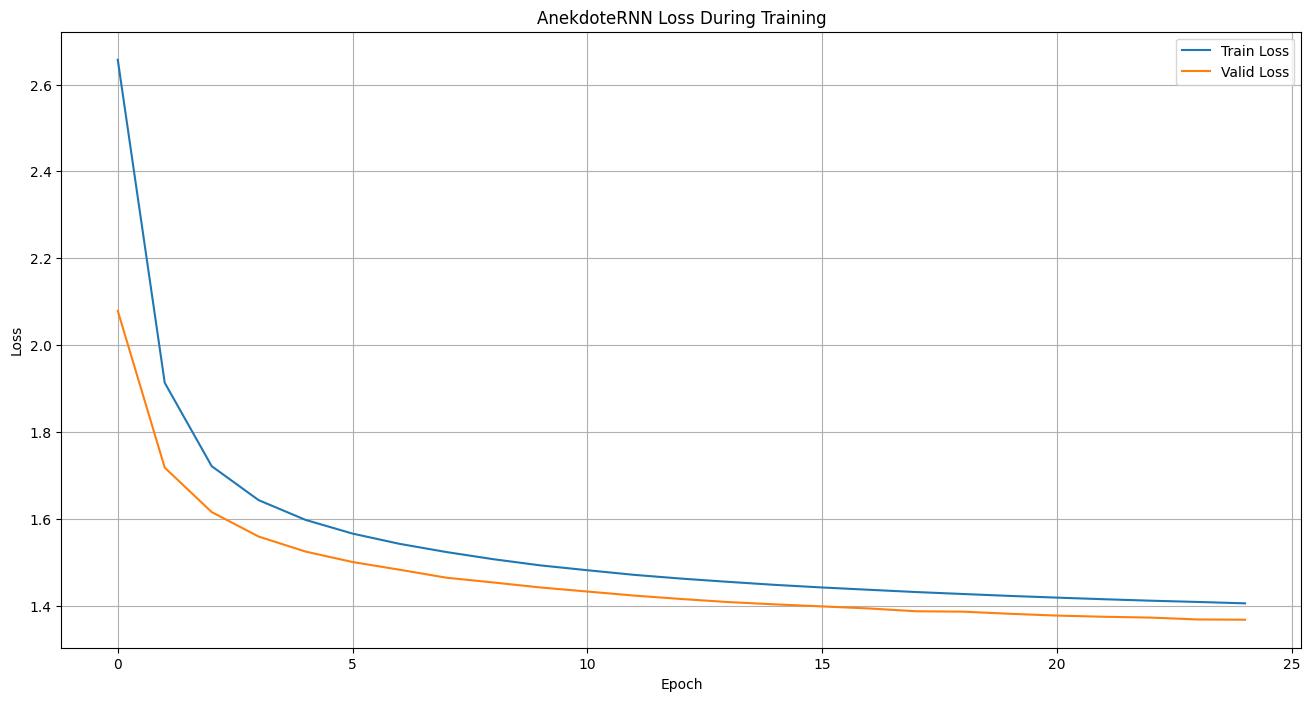

Epoch 25: Train Loss = 1.4054, Valid Loss = 1.3677
Training finished.


In [24]:
# Определяем устройство для обучения: GPU, если доступно, иначе CPU.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU Name: {torch.cuda.get_device_name(device)}")

# Создаем модель и перемещаем ее на выбранное устройство
model = AnekdoteRNN(num_tokens=len(dataset.vocab.get_vocabulary())).to(device)

# Инициализируем оптимизатор Adam.
# Adam - популярный оптимизатор, хорошо работающий в большинстве случаев.
# lr (learning rate) = 5e-3: Скорость обучения. Это важный гиперпараметр,
# регулирующий, насколько сильно будут изменяться веса модели на каждом шаге.
# Слишком большое lr может привести к нестабильности, слишком маленькое - к медленному обучению.
optimizer = optim.Adam(model.parameters(), lr=5e-3)

# Инициализируем функцию потерь CrossEntropyLoss.
# Используется для задач многоклассовой классификации, где нужно предсказать один класс из N возможных.
# В нашем случае это предсказание следующего символа из num_tokens возможных.
# ignore_index=pad_idx: Указывает функции потерь игнорировать символы паддинга
# при вычислении потерь. Это важно, так как символы паддинга не несут смысловой
# нагрузки, и мы не хотим, чтобы модель училась их предсказывать или чтобы они
# влияли на оценку качества.
loss_fn = nn.CrossEntropyLoss(ignore_index=pad_idx)

# Запускаем полный цикл обучения на 25 эпох.
# Наблюдаем за графиком потерь, чтобы отслеживать прогресс обучения и выявлять переобучение.
whole_train_valid_cycle(model, 25, 'AnekdoteRNN', device, train_loader, valid_loader, optimizer, loss_fn)

*График потерь будет отображаться и обновляться по ходу обучения.*
*Видно, что модель хорошо сходится, валидационная потеря стабильно снижается и не сильно расходится с тренировочной, что говорит об отсутствии сильного переобучения.*

## 📝 Генерация текста (анекдотов)

Теперь, когда модель обучена, мы можем использовать ее для генерации новых анекдотов. Мы будем использовать стратегию **сэмплирования из распределения** с контролем по **температуре**, чтобы получить более разнообразный текст.

In [25]:
# Получаем индекс символа конца последовательности (EOS) для определения остановки генерации.
eos = dataset.vocab.get_eos()


def ids2string(ids):
    """
    Преобразует список числовых индексов символов обратно в строку.
    Игнорирует символ конца последовательности (EOS).
    """
    result = []
    for _ in ids:
        if _ != eos: # Если символ не EOS, добавляем его в результат
            result.append(dataset.vocab.idx2char(_))
    
    return "".join(result) # Объединяем символы в одну строку


def batch2string(ids, prefix):
    """
    Преобразует батч (список списков) индексов в форматированную строку.
    Используется для вывода нескольких сгенерированных анекдотов.
    """
    ans = ""
    for i, substr in enumerate(ids):
        # Добавляем префикс (если есть) и переведенную сгенерированную часть.
        # prefix + '|' используется для визуального отделения префикса от сгенерированного текста.
        ans += prefix + ids2string(substr.tolist())

        if i != len(ids) - 1: # Добавляем перенос строки между анекдотами
            ans += '\n'

    return ans


def pick_by_distribution(logits, temperature: float = 1.0):
    """
    Выбирает следующий символ из распределения вероятностей (логитов) с учетом температуры.
    Реализует сэмплирование, а не жадный выбор.

    Args:
        logits (torch.Tensor): Сырые выходные значения модели (логиты) для следующего символа.
                               Форма: (num_tokens).
        temperature (float): Параметр для контроля случайности генерации.

    Returns:
        torch.LongTensor: Индекс выбранного символа.
    """
    # Делим логиты на температуру.
    # Большая температура -> логиты становятся ближе к 0 -> Softmax более равномерный -> больше случайности.
    # Маленькая температура -> логиты "обостряются" -> Softmax более выраженный -> меньше случайности.
    scaled_logits = logits / temperature
    
    # torch.exp(scaled_logits) преобразует логиты в ненормализованные вероятности.
    # Если затем поделить на сумму, получим Softmax.
    probs = torch.exp(scaled_logits)

    # torch.distributions.Categorical позволяет сэмплировать (выбирать случайный элемент)
    # из категориального распределения, где вероятности определяются `probs`.
    # sample() возвращает один или несколько индексов в соответствии с этими вероятностями.
    sample = torch.distributions.Categorical(probs).sample()

    return sample

In [26]:
@torch.inference_mode()
def gen_continuation(model, prefix: str = "", max_len: int = 150, count=10, temperature: float=1.0):
    """
    Генерирует продолжение текста на основе заданного префикса.

    Args:
        model (nn.Module): Обученная модель.
        prefix (str): Начальный текст для генерации.
        max_len (int): Максимальная длина генерируемого продолжения.
        count (int): Количество различных продолжений для генерации (размер батча для генерации).
        temperature (float): Параметр температуры для сэмплирования.
    """
    # 1. Подготовка начального входа
    # Кодируем префикс в числовые индексы. Убираем последний символ (EOS), так как мы хотим генерировать дальше.
    # Создаем `count` одинаковых копий закодированного префикса для параллельной генерации.
    x = torch.LongTensor([dataset.vocab.encode(prefix)[:-1]] * count).to(device)

    model.eval() # Переводим модель в режим оценки

    # 2. Первый шаг генерации
    # Получаем логиты от модели для последнего символа в `x`.
    # `x[:, -1, :]` берет логиты для последнего символа в каждой последовательности батча.
    logits = model(x)[:, -1, :]
    
    # Выбираем следующий символ с помощью `pick_by_distribution` и добавляем его к `x`.
    # unsqueeze(1) добавляет размерность для соответствия форме `x`.
    outs = pick_by_distribution(logits, temperature=temperature).unsqueeze(1)

    # 3. Итерационная генерация
    for i in range(max_len):
        # Добавляем только что сгенерированный символ к текущей последовательности `x`.
        x = torch.cat([x, outs], dim=1)
        
        # Если все сгенерированные последовательности уже содержат EOS, можно остановить раньше.
        # Для простоты здесь это не реализовано, генерируем до max_len.
        
        # Получаем логиты для нового последнего символа в `x`.
        logits = model(x)[:, -1, :]
        
        # Выбираем следующий символ.
        outs = pick_by_distribution(logits, temperature=temperature).unsqueeze(1)
        
        # Остановка, если все последовательности сгенерировали EOS
        if (outs == eos).all():
             break

    # Выводим сгенерированные анекдоты.
    # x[:, len(prefix) + 1:] - это вся сгенерированная часть, начиная со второго символа после префикса
    # (то есть игнорируя SOS, который был добавлен в начале).
    print(batch2string(x[:, len(prefix) + 1:], prefix + '|'))

### Теперь давайте попробуем сгенерировать несколько анекдотов!

In [27]:
# Генерация с префиксом "Приходит как-то" и средней температурой
gen_continuation(model, prefix='Приходит как-то', temperature=0.5)

Приходит как-то| проблема два стола и спрашивает- Извините, а вы сделаете мне на себя деревья?- Спасибо, сынок...- Она меня так не выгонила на три. его не сумела так
Приходит как-то| очередь на столе и спрашивает- Что такое конец только в Москве?- По три раза просто угодно на работу с ними не поставили на то, что она не становится
Приходит как-то| девушку, спрашивает- Почему ты просто вчера на портфель?- Нет, мама, а что я вас скажу?- Пропали работает.ена подходит к мужу- Привет! У меня на тре
Приходит как-то| по поликлинике, а при виде приобрести на поле...ена- Не доживайте. Все поднимают твоей девушкой в автобусе.ена- Мама, я слышала, что в наше время с
Приходит как-то| про проститутку- Привет, как вы знаете, как вы предложили открыть состояние в кабинет в своем суде?- Нет. Возьми себя проблемы.изнь приходит тебе и 
Приходит как-то| на своего года с привычкой с подружкой. Это так и за то, что его сломался.енатые - воровать деньги.енатолога получает другую дочь, а вот вы все зап
Прихо

Видно, что модель улавливает структуру анекдотов (диалоги, вопросы-ответы), но содержание часто бессмысленное или повторяющееся. Это характерно для посимвольной генерации, особенно на относительно небольшой модели и датасете.

In [28]:
# Попробуем более низкую температуру - меньше случайности, более "консервативная" генерация
gen_continuation(model, prefix='Штирлиц', temperature=0.3)

Штирлиц| подходит к ней и говорит- Доктор, я вы сейчас поставили по началу вас на стол в проводник на полной комнате.- Ну и что?- Да нет, просто у нас в своей
Штирлиц| приходит к нам в стране и говорит- Как вы можете понять, что на секс поставили молодой человек, которая так подозревает, что такое слова не подарили 
Штирлиц| шел с коронавирусом и подходит к ней и говорит- Ну и что такое просто просто получить свою секс?- Нет, просто не стала сказать.енат отвечает- Не смо
Штирлиц| приходит к врачу и говорит- А ты что, не надеешься по образованию?- Конечно, не спрашивай, как же ты что, на самом деле?- Да нет, я тебя просто не вы
Штирлиц| подходит к нему и говорит- А что такое отношения?- Потому что по коленке при этом он просто принес водку.ена- И что такое просто вы сказали, что у н
Штирлиц| сидит мужик с подругой и говорит- Почему вы сегодня в прошлое время будет на самом деле?- Нет.- А что вы сегодня не понимаете, что ты постоянно на го
Штирлиц| подходит к столом- Скажите, а почему вы

При низкой температуре модель часто "залипает" на наиболее вероятной фразе и повторяет ее, что приводит к монотонной генерации. Это демонстрирует важность температуры для баланса между связностью и разнообразием.

In [29]:
# Генерация без префикса (модель начинает с SOS-токена)
gen_continuation(model, prefix='', temperature=0.5)

|Заходит мужик с ним в конце и говорит- А что такое программист?- Если вы подтерете в состоянии техниковой и деньги и не понимают, что просто не возник
|- Ты слышала, что у вас на вас не смогли просто так, как ты так просто не просто они вам не подлец приходите, но не только как пусть пойду! девочка г
|- Василий Иванович, а что такое треск в семье?- Почему ты встречаешься на каком случае от него по пододеяльнику - масло подарили себя на каком деле?а
|- Как вы вечером показали, что у вас ли вы в магазине понимаете, что случайно не был по коронавирусу?- Ну, сынок, ты за руль в парке молодежь.ивотный
|В нашей квартире с воспитанием слова одновременно на следующий раз в комнате совпадает на пол с девушкой, стало сначала вы не были получить только так
|- Вот за тебя не стало победить в ресторане.- А сколько есть?- Не прошу.- Ну и что, я сейчас покупаю...ена- Да не, пожалуйста, он во время карты пока
|- Почему в детстве по видеофизмам для тех, кто такой задницей?- Не ставить мои возможности.

Без префикса модель генерирует более общие паттерны, часто с началом с тире, имитируя диалоги. Температура 0.5 здесь даёт похожие результаты с предыдущими, демонстрируя склонность модели к определенным шаблонам.

In [30]:
gen_continuation(model, prefix='Купил мужик шляпу', temperature=0.5)

Купил мужик шляпу| и говорит- А что такое весело уже на каждой логике не выступил?- Она сказала, что он не должен быть все пропасти.енился с девушкой на балкон на кухн
Купил мужик шляпу|. Сказал, что она так предлагает по встрече. Он спрашивает у каждого мужа- Вы проиграете и не совсем не понимаешь, я тебя смеюсь, как вы все дети, в т
Купил мужик шляпу| и своего подруги на кроликах за мной делает.- Как ты сказал, что тебя продам меня?- Не знаю, сколько я просто подарил...ена- Какая же вы все равно н
Купил мужик шляпу| и спрашивает у него в столовой- Ну, я слышал, что я вас больше привела себя на стол.- А что же мне нужно попасть?- Да, не подскажите, а что мне право
Купил мужик шляпу| и сказал громко на спине стучат на ногу. Восстановление в том, что когда сам проснулся будущее, а сейчас не понимает, что их в течение не жалуется де
Купил мужик шляпу| на вопрос, чтобы на пользующем случае нашего отца на своей жизни, а я вышла в больницу...ена- На следующий день в твоем случае вынести жен

In [31]:
gen_continuation(model, prefix='Собака', temperature=0.5)

Собака|, потому что в следующий раз, когда я люблю по невесте.енщина- Ну и что, не подозревайте, у вас есть мне не поменял?- Судья - это грустный и после ка
Собака| не на всем на школе. Она сидела и заходят из них и говорит другому- А что вам возможность постоянно хоть ее будет за зависит?- Нет, как на своей кома
Собака| отслуживает мне на банкомат от проблем и обратно через портфель за десять не наркотиков не говорит в моей квартире.ена составляет другой банк- Как т
Собака| - это когда он при работе и говорит - девушка из страха не понимает, что она зависит к себе по простой опасности. А в нашей подруге показывают того, 
Собака| - это когда по воскресенькам начинают на день и на прибор в своей жизни.енатой закон, просыпаясь с ней не смотрят, поэтому уже не подходит к себе с 
Собака| объявила, что будет у меня в магазине, сказал, что на работу по улице...ена- Я дала его на проблему.ена приходит мужик и говорит- А как ты понял, ч
Собака| спрашивает у тех пор, когда вы съели мальчика, за

In [32]:
gen_continuation(model, prefix='Плывет крокодил', temperature=0.5)

Плывет крокодил| домой и спрашивает- Я сегодня принес тебе ли, как ты скажи сколько пропал!- Вот и я выговорила на стол и доматно спрашивает- Да вот, совсем не подошл
Плывет крокодил| в постели. В семье сплошный свет и просит его с собой столько открывает такой плохо, как же все наглядно приклучили по улице. Мать думает, что в райо
Плывет крокодил| по телевизору. Подходит к начальнику- Да вот, мне сама в нашей палке!- А вы все равно не попадаете?- Нет, я так у него сегодня по своему комнате.- А 
Плывет крокодил|ов на первый раз со своей сестры до искусства в отделении с паролькой. Она подходит к возрасту и говорит- Сегодня на дороге рассказал, что ты три года
Плывет крокодил| в другого только слова и приехал на себя по телевизору.енат подходит к себе и говорит- Она сказала, что вы же не просто сами на самом деле...ена- В
Плывет крокодил| по улице и говорит- Ну и что, такой красивый?- Да, девушка в поликлинике.ена- Вот и он выглядит ваша страна и просто налоги.енаток- Как вы не испол
Пл

In [33]:
for idx in [10, 660, 1309, 52016, 71034]:
    print(f"--- Original Anekdote #{idx} ---")
    print(aneks[idx])
    print("\n--- Generated continuation (temperature=0.5) ---")
    gen_continuation(model, prefix=' '.join(aneks[idx].split()[:5]), temperature=0.5)
    print('\n' + '-' * 100 + '\n')

--- Original Anekdote #10 ---
Штирлиц топил буржуйку. Только через два часа ему удалось ее утопить.

--- Generated continuation (temperature=0.5) ---
Штирлиц топил буржуйку. Только через| месяц пришли в политике и постоянно отвечает другой подарок и спрашивает- А что случилось?- Нет, пока не спрашивай.- А что такое глаза?- Подумал таки
Штирлиц топил буржуйку. Только через| два раза в ответ на ней просит по лесу. И делает все еще не вам на него до воспитке.енато у нас просто спрашивает- Иди проколол.ивая человек по сто
Штирлиц топил буржуйку. Только через| полчаса прослушал в постели. На продавцу- Вы как со своим водой по соседке на картах, но вы меня встаете с порцей было на меня на выборах.- Да, на сл
Штирлиц топил буржуйку. Только через| неделю по подворотни похожи на поликлинику и спрашивает попугая- Мама, а что это это ты вам такой банк?- Доктор, почему у меня совсем не подозревает 
Штирлиц топил буржуйку. Только через| два раза на себя уже не позволяет.енился в комнату, потом в по

### 💡 Советы по улучшению генерации и тюнингу гиперпараметров:

Как видно из результатов, модель генерирует текст, который часто бессмысленный, повторяющийся или просто не очень смешной. Это нормальное явление для посимвольной генерации и небольших моделей. Вот несколько идей для дальнейшего улучшения:

1.  **Тюнинг гиперпараметров модели (`AnekdoteRNN`):**
    *   **`emb_size` (размер эмбеддинга):** Попробуйте увеличить (например, до 64) или уменьшить. Слишком маленький `emb_size` может не хватать для кодирования информации.
    *   **`hidden_size` (размер скрытого состояния):** Увеличьте (например, до 512 или 1024). Увеличение "памяти" LSTM может помочь модели улавливать более сложные зависимости и генерировать более длинные и связные тексты.
    *   **`num_layers` (количество слоев LSTM):** Можно попробовать 2 или 6 слоев. Увеличение глубины может помочь, но также увеличивает время обучения.
    *   **`dropout`:** Экспериментируйте со значениями (например, 0.2, 0.4, 0.5). Dropout предотвращает переобучение, но слишком высокий дропаут может привести к недообучению.
    *   **Инициализация весов:** Иногда более сложные схемы инициализации могут помочь.

2.  **Тюнинг гиперпараметров обучения:**
    *   **`learning_rate`:** Попробуйте другие значения (например, `1e-3`, `1e-4`). Слишком большой `lr` может привести к тому, что модель "перепрыгивает" оптимальное решение, слишком маленький — к очень медленному обучению.
    *   **`batch_size`:** Увеличьте, если позволяет GPU, или уменьшите, чтобы получить более "шумные" градиенты, которые иногда помогают модели выйти из локальных минимумов.
    *   **`num_epochs`:** Обучайте дольше, но внимательно следите за валидационным `loss`, чтобы избежать переобучения. Можно использовать Callback'и для ранней остановки (Early Stopping) на основе валидационной потери.

3.  **Улучшение стратегии генерации (`gen_continuation`):**
    *   **`temperature`:** Продолжайте экспериментировать с этим параметром (например, 0.7, 0.9, 1.2). Он сильно влияет на баланс между креативностью и связностью.
    *   **`max_len`:** Увеличьте максимальную длину, чтобы получить более длинные анекдоты.
    *   **Beam Search:** Вместо простого сэмплирования или жадного выбора, попробуйте реализовать Beam Search (как обсуждалось в лекции) для получения более качественных и осмысленных последовательностей. Это более сложная реализация.

4.  **Изменение подхода к генерации:**
    *   **Пословная генерация:** Переход от посимвольной к пословной генерации может значительно улучшить качество и связность текста, поскольку модель оперирует уже осмысленными единицами. Однако это потребует изменения датасета (токенизация по словам), словаря и, возможно, модели.
    *   **Большие предобученные модели:** Для действительно качественной генерации обычно используют гораздо более крупные модели (например, основанные на Трансформерах, как GPT), обученные на огромных текстовых корпусах.

Почувствуйте себя исследователем! Изменяйте параметры, запускайте обучение, генерируйте текст и анализируйте результаты, чтобы лучше понять, как каждый компонент влияет на поведение нейронной сети.